# Phase 1 — GSM8K data preparation

The logic lives in `scripts/` and `src/data/` (the notebook only calls it), so results are identical whether run here or from the terminal.
Details: `docs/DATA_REPORT.md`. Kernel: **Python 3.12 (RL_Project .venv)**.

In [1]:
import subprocess, sys
from pathlib import Path

ROOT = Path.cwd()
print("python:", sys.executable)

def run(*args):
    r = subprocess.run([sys.executable, *args], cwd=ROOT, capture_output=True, text=True)
    print(r.stdout[-3000:], r.stderr[-2000:], sep="")
    if r.returncode != 0:
        raise RuntimeError(f"{args} failed with exit code {r.returncode}")

run("scripts/download_data.py")   # skips if raw files already match manifest hashes
run("scripts/prepare_data.py")

python: C:\Users\EGY SKY\Desktop\RL_Project\.venv\Scripts\python.exe
[ok] raw files already present and hashes match manifest (commit 3101c7d507)



[ok] processed splits written to C:\Users\EGY SKY\Desktop\RL_Project\data\processed\gsm8k
     train              6726
     validation         747
     test               1319
     train_small        500
     validation_small   100
     test_small         200
     excluded from train pool: 0
     invalid raw records: train 0 test 0
     test internal duplicate groups: 0
     exact overlap after split: {'train_validation': 0, 'train_test': 0, 'validation_test': 0}
     near-dups (J>=0.8) test~dev: 0  val~train: 0
     shared templates, numbers masked (J>=0.8) test~dev: 2  val~train: 1



In [2]:
run("scripts/validate_data.py")
run("-m", "pytest", "-q", "--color=no")

[PASS] raw train: sha256 matches download manifest
[PASS] raw train: record count == manifest (7473)
[PASS] raw test: sha256 matches download manifest
[PASS] raw test: record count == manifest (1319)
[PASS] raw: official sizes 7473 / 1319
[PASS] raw: license file is MIT
[PASS] train: file sha256 matches split_manifest
[PASS] train: ids match split_manifest (order incl.)
[PASS] train: split_ids/train.txt matches
[PASS] train: ids unique
[PASS] train: all required fields present, no extras
[PASS] train: split field == 'train'
[PASS] validation: file sha256 matches split_manifest
[PASS] validation: ids match split_manifest (order incl.)
[PASS] validation: split_ids/validation.txt matches
[PASS] validation: ids unique
[PASS] validation: all required fields present, no extras
[PASS] validation: split field == 'validation'
[PASS] test: file sha256 matches split_manifest
[PASS] test: ids match split_manifest (order incl.)
[PASS] test: split_ids/test.txt matches
[PASS] test: ids unique
[PASS] 

........................................................................ [ 67%]
...................................                                      [100%]
107 passed in 0.67s



In [3]:
import json

PROC = ROOT / "data" / "processed" / "gsm8k"
report = json.loads((PROC / "data_report.json").read_text(encoding="utf-8"))
val = json.loads((PROC / "validation_result.json").read_text(encoding="utf-8"))

print("raw counts:      ", report["raw_counts"])
print("processed counts:", report["processed_counts"])
print("excluded:        ", report["excluded_from_train_pool"]["by_reason"] or "none")
print("exact overlap:   ", report["overlap_checks"]["exact_normalized_text_overlap_after_split"])
print("answer formats:  ", report["answer_formats"])
print(f"validation:       {val['n_checks'] - val['n_failed']}/{val['n_checks']} checks passed")

example = json.loads((PROC / "test_small.jsonl").read_text(encoding="utf-8").splitlines()[0])
print("\nexample record:")
for k, v in example.items():
    print(f"  {k:24s} {str(v)[:110]!r}")

raw counts:       {'train': 7473, 'test': 1319}
processed counts: {'train': 6726, 'validation': 747, 'test': 1319, 'train_small': 500, 'validation_small': 100, 'test_small': 200}
excluded:         none
exact overlap:    {'train_validation': 0, 'train_test': 0, 'validation_test': 0}
answer formats:   {'train_raw': {'has_thousands_separator': 79, 'integer_value': 7473, 'negative': 3}, 'test_raw': {'has_thousands_separator': 14, 'integer_value': 1319, 'negative': 2}}
validation:       58/58 checks passed

example record:
  id                       'gsm8k-test-00025'
  source_split             'test'
  source_line              '26'
  split                    'test'
  question                 'Marie ordered one chicken meal that costs $12, 5 packs of milk that costs $3 each, 4 apples that cost $1.50 ea'
  reference_solution       'Five packs of milk cost $3 x 5 = $<<3*5=15>>15.\nFour apples cost $1.50 x 4 = $<<1.5*4=6>>6.\nThe total cost of '
  reference_final_answer   '2'
  normalized_fina

# Phase 2 — Solver + Verifier + RL Coordinator

Heavy steps run from the terminal (see README): generation cache, `train_coordinator.py` (validation-only selection), `evaluate.py`.
The cells below **read the real result files** and run one live question. Nothing here recomputes or changes results.

In [4]:
import json

def table(split):
    m = json.loads((ROOT / "results" / "eval" / split / "metrics.json").read_text(encoding="utf-8"))
    print(f"== {split}  (n={m['meta']['n_problems']}, {m['meta']['generation_mode']})")
    print(f"{'method':18s} {'acc':>6s} {'95% CI':>15s} {'attempts':>8s} {'PoT':>5s} {'calls':>6s} {'out_tok':>7s} {'lat_s':>6s} {'return':>7s}")
    for k in ["A_single_attempt", "B_fixed_rule", "C_rl", "ref_max_budget"] + [f"C_rl_seed{i}" for i in range(5)]:
        s = m["metrics"][k]
        lo, hi = s["accuracy_ci95_wilson"]
        print(f"{k:18s} {s['accuracy']:6.3f} [{lo:.3f}, {hi:.3f}] {s['mean_attempts']:8.2f} {s['mean_pot_calls']:5.2f} "
              f"{s['mean_model_calls']:6.2f} {s['mean_output_tokens']:7.0f} {s['mean_latency_s']:6.2f} {s['mean_return']:+7.3f}")
    seeds = m["metrics"]["C_rl_across_seeds"]
    print(f"RL across {seeds['n_seeds']} seeds: accuracy {seeds['accuracy_mean']:.3f} ± {seeds['accuracy_std']:.3f}")
    for name, c in m["comparisons"].items():
        d = c["accuracy_diff_bootstrap"]
        print(f"  {name:34s} {d['diff']:+.3f}  CI95 [{d['ci95'][0]:+.3f}, {d['ci95'][1]:+.3f}]  McNemar p={c['mcnemar_exact']['p_value']:.3g}")
    print()

table("test_small")
table("test")

== test_small  (n=200, cached replay of pre-generated attempts)
method                acc          95% CI attempts   PoT  calls out_tok  lat_s  return
A_single_attempt    0.480 [0.412, 0.549]     1.00  0.00   1.00     305   0.38  -0.040
B_fixed_rule        0.535 [0.466, 0.603]     2.50  1.00   3.50     921   1.07  -0.035
C_rl                0.490 [0.422, 0.559]     1.24  0.10   1.34     400   0.49  -0.035
ref_max_budget      0.530 [0.461, 0.598]     4.00  1.00   5.00    1334   1.53  -0.120
C_rl_seed0          0.540 [0.471, 0.608]     3.55  0.97   4.52    1209   1.39  -0.077
C_rl_seed1          0.490 [0.422, 0.559]     1.24  0.10   1.34     400   0.49  -0.035
C_rl_seed2          0.530 [0.461, 0.598]     2.63  0.99   3.62     958   1.11  -0.051
C_rl_seed3          0.515 [0.446, 0.583]     3.67  0.74   4.42    1208   1.37  -0.126
C_rl_seed4          0.490 [0.422, 0.559]     1.18  0.14   1.31     385   0.48  -0.033
RL across 5 seeds: accuracy 0.513 ± 0.020
  B_fixed_rule - A_single_attempt

In [5]:
# One real XAI record from the test logs (example selected deterministically by scripts/select_examples.py)
ex = json.loads((ROOT / "results" / "examples" / "examples_test.json").read_text(encoding="utf-8"))["rl_fixed_it"][1]
print(ex["problem_id"], "| reference:", ex["reference_answer"])
print("Q:", ex["question"])
print("A:", ex["A"], "\nB:", ex["B"]["answer"], ex["B"]["actions"])
print("C:", ex["C"]["answer"], ex["C"]["actions"], "attempt answers:", ex["C"]["attempt_answers"])
for t in ex["C"]["explanations"]:
    print(" -", t)

gsm8k-test-00026 | reference: 243
Q: Mishka bought 3 pairs of shorts, 3 pairs of pants, and 3 pairs of shoes. One pair of shorts costs $16.50. One pair of pants costs $22.50 and one pair of shoes costs $42. How many dollars did Mishka spend on all the clothing items?
A: {'answer': '233', 'correct': False} 
B: 243 ['VERIFY_MORE', 'REGENERATE', 'ACCEPT']
C: 243 ['REGENERATE', 'REGENERATE', 'VERIFY_MORE', 'REGENERATE', 'ACCEPT'] attempt answers: ['233', '243', '233', '243']
 - Chose REGENERATE (Q=+0.086) over VERIFY_MORE (Q=-0.067), margin +0.152. Signals: 1 attempt(s); candidate 233 supported by 1; arithmetic error found; PoT not run. Q = expected return under the designed reward, not a probability of correctness.
 - Chose REGENERATE (Q=-0.143) over VERIFY_MORE (Q=-0.228), margin +0.085. Signals: 2 attempt(s); candidate 243 supported by 1; arithmetic consistent; PoT not run. Q = expected return under the designed reward, not a probability of correctness.
 - Chose VERIFY_MORE (Q=+0.308) o

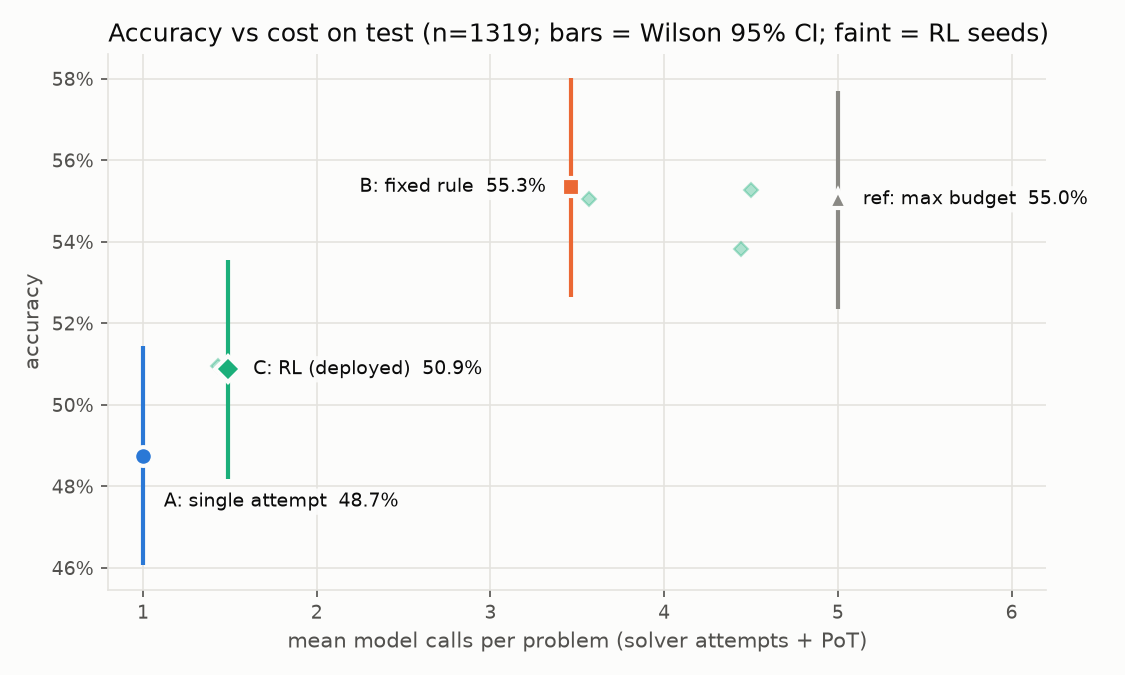

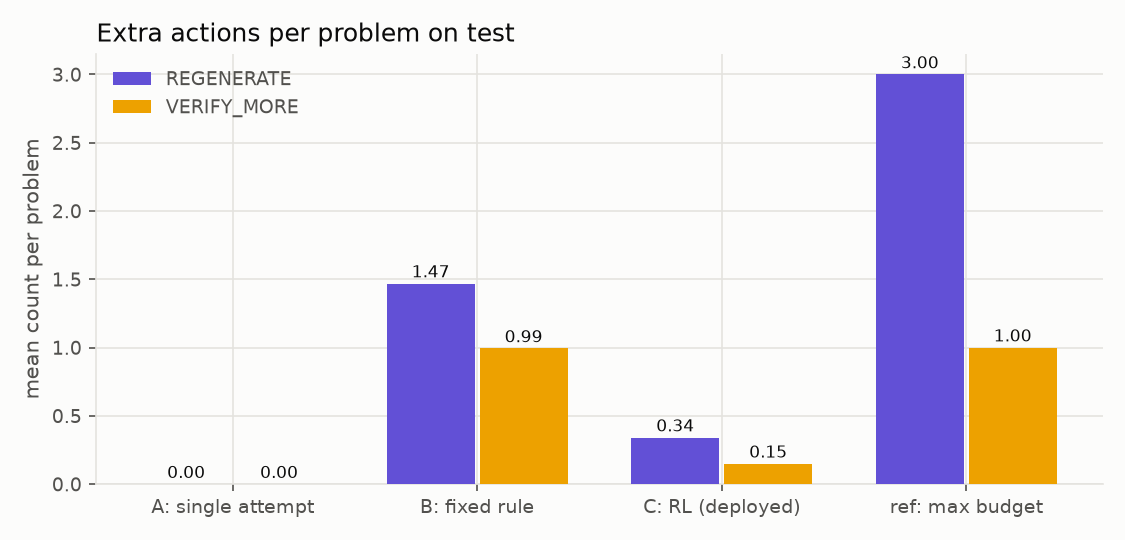

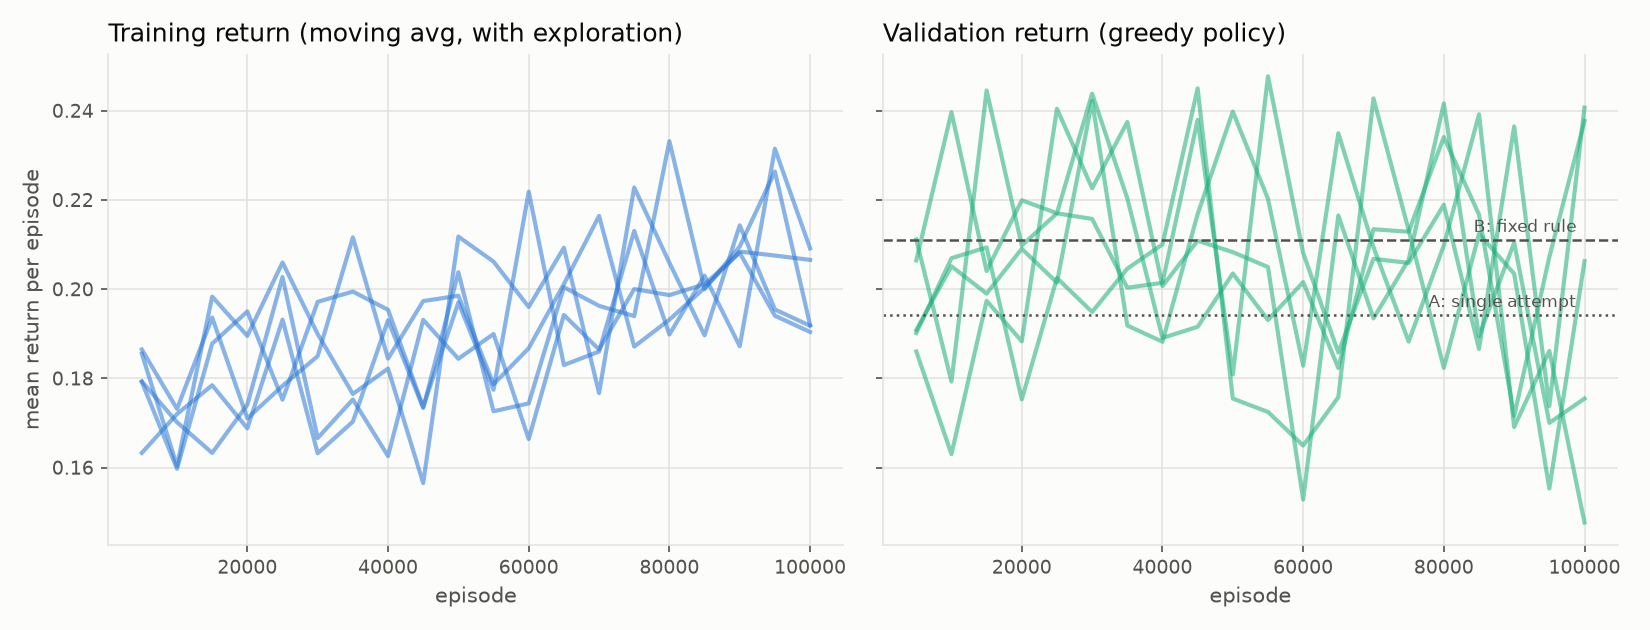

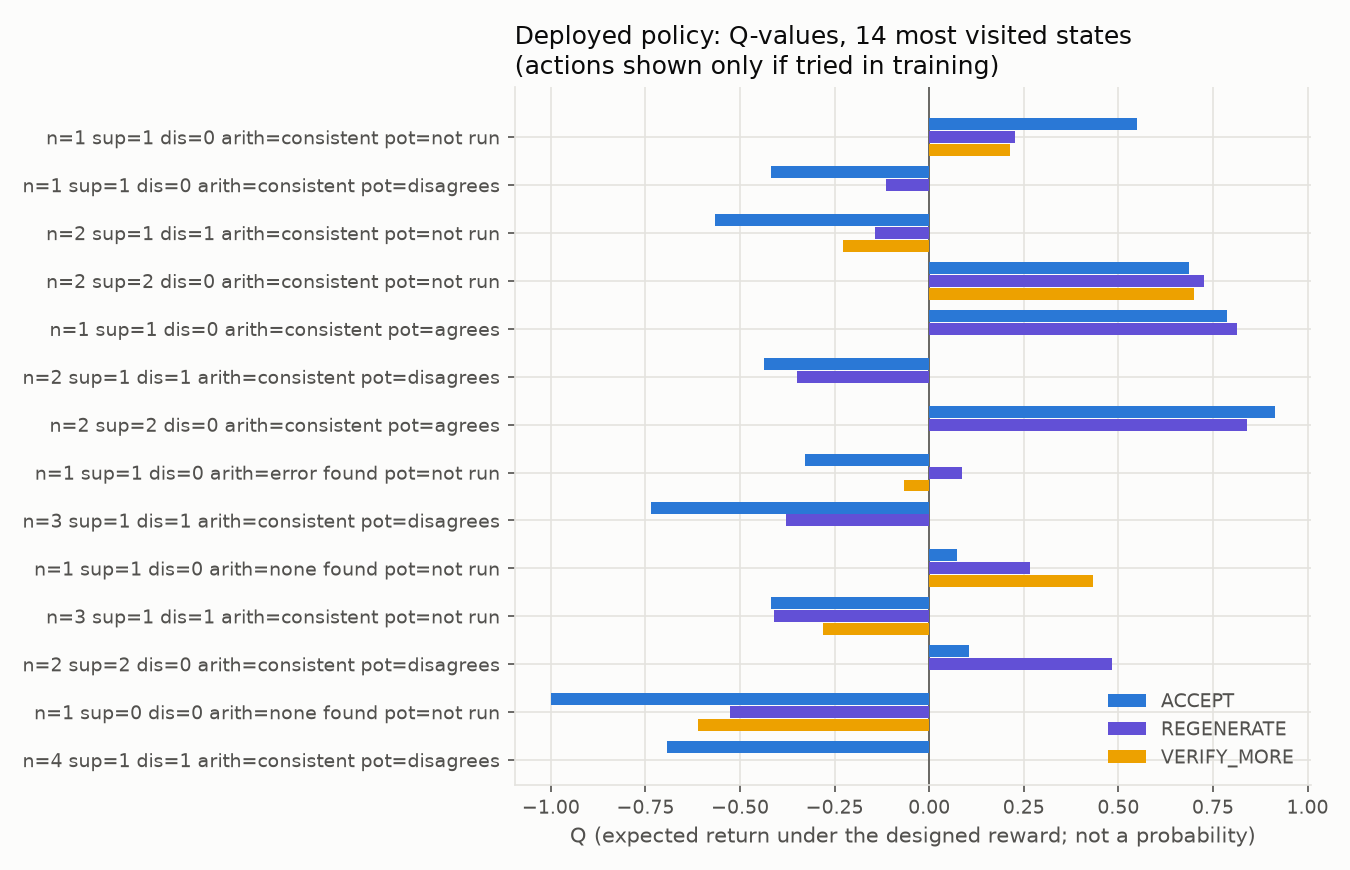

In [6]:
from IPython.display import Image, display

for f in ["accuracy_vs_cost_test.png", "actions_test.png", "learning_curves.png", "policy_qvalues.png"]:
    display(Image(filename=str(ROOT / "results" / "figures" / f), width=760))

In [7]:
# Live: a NEW question (not from GSM8K), no reference answer. Loads Qwen once (GPU), then runs the RL coordinator.
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
sys.path.insert(0, str(ROOT))
from src.pipeline import solve_problem

r = solve_problem("Sara has 5 boxes with 12 pencils each. She gives away 17 pencils. How many pencils does she have now?",
                  method="rl", budget=4, seed=0)
print("final answer:", r["final_answer"], "|", r["termination_reason"], "| actions:", " -> ".join(r["actions"]))
print("usage:", r["usage"], "| live generation s:", round(r["latency_s"]["generation"], 2))
for d in r["explanations"]:
    print(" -", d["text"])

C:\Users\EGY SKY\Desktop\RL_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 15:49:29.566000 47968 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/290 [00:00<00:32,  8.76it/s]

Loading weights:   1%|          | 2/290 [00:00<00:59,  4.87it/s]

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 733.84it/s]

final answer: 43 | accepted | actions: ACCEPT
usage: {'attempts': 1, 'model_calls': 1, 'verifier_calls': 1, 'input_tokens': 73, 'output_tokens': 166} | live generation s: 7.09
 - Chose ACCEPT (Q=+0.549) over REGENERATE (Q=+0.226), margin +0.322. Signals: 1 attempt(s); candidate 43 supported by 1; arithmetic consistent; PoT not run. Q = expected return under the designed reward, not a probability of correctness.
